In [8]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

ROOT = Path.cwd()
while not (ROOT / "cf").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import optuna
import torch

from cf.data import RatingData
from cf.features import GenreData, GenreProfile, TitleData, YearData, on_film_nodes
from cf.graph import RatingGraphs
from cf.models.imc_gae import IMCGAE, GenreTerms, SumTerms
from cf.trainer import Trainer
from experiments.paths import GENRES_DATA_PATH, TEST_DATA_PATH, TRAIN_DATA_PATH

print("repo root:", ROOT)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
repo root: /Users/aaronaidoudi/Downloads/IMC-GAE-GROUP


In [9]:
RUN_BASE_NAME = "final2110"

VARIANT = {
    # Named pieces added to the starting vector; genre_year contains normalized
    # genre weights plus one standardized release-year value.
    # Examples: "none", "genre_year", "title", "genre_year+title".
    "features": "genre_year",
    "side": False,               # optional genre rating-profile term added to scores
    "use_bias": False,           # learned level / user / item biases added to the scores
    "layer_weights": False,     # no layer matrices; ReLU only after the final propagation layer
    "share_feature_weights": True,  # reuse each feature projection across all rating levels
    "optimizer": "adam",         # "adam" gave the best validation RMSE; "adamw" memorises
}
RUN_NAME = f"{RUN_BASE_NAME}_{'with' if VARIANT['layer_weights'] else 'without'}_layer_weights"

TITLE_PCA_DIM = 16               # title vectors: 384 numbers reduced to this many
SEED = 0
N_SPLITS = 3                     # folds of the cross-validation
N_TRIALS = 40                    # Optuna trials
MAX_EPOCHS = 600                 # cap per training; early stopping usually ends sooner
EVAL_EVERY = 5                   # validate every 5 epochs
PATIENCE = 8                     # stop after 8 validations (40 epochs) without progress

In [10]:
data = RatingData(np.load(TRAIN_DATA_PATH))
names_genres = np.load(GENRES_DATA_PATH, allow_pickle=True)
genres = GenreData(names_genres)
years = YearData(genres.titles)
assert genres.n_items == data.n_items, "genre file and rating matrix disagree on the number of films"

# Combine row-normalized genre weights with one standardized numeric year.
# The last column of genre_year is the normalized release year.
genre_year = genres.with_normalized_year(years)                       # (n_items, n_genres + 1)
ALL_FEATURES = {
    "genre_year": on_film_nodes(genre_year, data.n_users),            # (N, n_genres + 1)
}
print(f"release year: mean={years.mean:.1f}, scale={years.scale:.1f}, "
      f"missing years={years.n_missing}; normalized range="
      f"[{years.normalized.min():.2f}, {years.normalized.max():.2f}]")

title_embedding_path = ROOT / "data" / "title_raw_titles_only.npy"
if title_embedding_path.exists():
    title_raw = np.load(title_embedding_path)                        # (n_items, 384)
    if title_raw.ndim != 2 or title_raw.shape[0] != data.n_items:
        raise ValueError(f"expected one title vector per film ({data.n_items}), got {title_raw.shape}")
    title_data = TitleData(genres.titles).set_raw(title_raw)
    ALL_FEATURES["title"] = on_film_nodes(title_data.reduced(k=TITLE_PCA_DIM), data.n_users)   # (N, 16)
else:
    title_data = None
    print(f"no title vectors at {title_embedding_path}: the 'title' feature is unavailable")


def pick_features(spec):
    """'none' -> None; 'genre_year+title' -> both named feature matrices."""
    if spec == "none":
        return None
    names = spec.split("+")
    missing = [name for name in names if name not in ALL_FEATURES]
    if missing:
        raise KeyError(f"unknown or unavailable feature(s) {missing}; available: {list(ALL_FEATURES)}. "
                       "For 'title', run experiments/embed_titles.py first.")
    return {name: ALL_FEATURES[name] for name in names}


features = pick_features(VARIANT["features"])
feature_names = tuple(features) if features else ()

print(f"ratings: {data.n_users} users x {data.n_items} items, {len(data.ratings)} observed")
print("rating levels:", data.levels)
print("available feature matrices:")
for name, matrix in ALL_FEATURES.items():
    users_zero = bool((matrix[:data.n_users] == 0).all())
    films = int((np.abs(matrix[data.n_users:]).sum(axis=1) > 0).sum())
    used = "USED" if name in feature_names else "not used"
    print(f"  {name:6s} {str(matrix.shape):12s} users all zero: {users_zero}   films with a row: {films}/{data.n_items}   {used}")
print("run:", RUN_NAME, VARIANT)


def build_side(train, params):
    """Genre-profile score term, built from this fold's training ratings only."""
    if not VARIANT["side"]:
        return None
    shrink = params["profile_shrink"]
    genre_profile = GenreProfile(train[0], train[1], train[2], genres.multi_hot,
                                 data.n_users, data.T, shrink=shrink)
    return SumTerms([GenreTerms(genre_profile.table(), genre_profile.Gn)])


def build_model(params, side, feats="variant"):
    """feats: the feature matrices to use; by default those selected in VARIANT."""
    return IMCGAE(
        data.n_users, data.n_items, data.T,
        d_shared=params["d_shared"], d_role=params["d_role"], d_personal=params["d_personal"],
        out_dim=params["out_dim"], n_layers=params["n_layers"],
        p0=params["p0"], theta=params["theta"],
        side=side,                                   # optional genre profile score term, or None
        use_bias=VARIANT["use_bias"],
        layer_weights=VARIANT["layer_weights"],
        share_feature_weights=VARIANT["share_feature_weights"],
        features=features if isinstance(feats, str) else feats,     # pieces of the starting vector
        d_feat=params.get("d_feat", 8),              # size of each feature piece
    )


def make_trainer(model, graphs, params, epochs, verbose=False):
    return Trainer(model, graphs, data.levels, lr=params["lr"], lam=params["lam"],
                   weight_decay=params["weight_decay"], optimizer=params["optimizer"],
                   epochs=epochs, eval_every=EVAL_EVERY, patience=PATIENCE, verbose=verbose)


print("\nmodel built from this configuration:")
print(build_model({"d_shared": 8, "d_role": 8, "d_personal": 8, "out_dim": 32, "n_layers": 1,
                   "p0": 0.1, "theta": 0.0, "d_feat": 8}, None).describe())

release year: mean=1994.8, scale=16.3, missing years=1; normalized range=[-5.68, 1.42]
ratings: 610 users x 4980 items, 31598 observed
rating levels: [0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5 5. ]
available feature matrices:
  genre_year (5590, 20)   users all zero: True   films with a row: 4980/4980   USED
  title  (5590, 16)   users all zero: True   films with a row: 4980/4980   not used
run: final2110_without_layer_weights {'features': 'genre_year', 'side': False, 'use_bias': False, 'layer_weights': False, 'share_feature_weights': True, 'optimizer': 'adam'}

model built from this configuration:
{'starting_vector': {'shared': 8, 'role': 8, 'genre_year': 8, 'personal': 8}, 'dim': 32, 'features': ['genre_year'], 'share_feature_weights': True, 'n_layers': 1, 'layer_weights': False, 'encoder_dense_bias': True, 'side': False, 'use_bias': False, 'n_parameters': 458680}


In [11]:
if title_data is None:
    print("no title vectors loaded")
else:
    print("text embedded for film 0:", repr(title_data.texts[0]))
    print("raw vectors:", title_data.raw.shape, "  after PCA:", ALL_FEATURES["title"][data.n_users:].shape)
    for query in ["Toy Story", "Jumanji", "Heat", "Tomb Raider", "Star Wars"]:
        try:
            print(" ", title_data.neighbours(query, k=4))
        except StopIteration:
            print("  no film matching", query)

text embedded for film 0: 'The movie Toy Story'
raw vectors: (4980, 384)   after PCA: (4980, 16)
  ('Toy Story (1995)', ['Inception (2010)', 'Ride with the Devil (1999)', 'That Awkward Moment (2014)', 'Bambi (1942)'])
  ('Jumanji (1995)', ['Omega Man, The (1971)', 'Conformist, The (Conformista, Il) (1970)', 'Legend of Bagger Vance, The (2000)', 'Juror, The (1996)'])
  ('Heat (1995)', ['Red 2 (2013)', 'Regarding Henry (1991)', 'Oliver! (1968)', "Ferris Bueller's Day Off (1986)"])
  ('Lara Croft: Tomb Raider (2001)', ['Made (2001)', 'Mr. Nice Guy (Yat goh ho yan) (1997)', 'Holy Smoke (1999)', 'Jungle2Jungle (a.k.a. Jungle 2 Jungle) (1997)'])
  ('Star Wars: Episode IV - A New Hope (1977)', ['Wings of Desire (Himmel über Berlin, Der) (1987)', 'Princess Bride, The (1987)', 'Mr. Nobody (2009)', 'Hook (1991)'])


In [12]:
check_params = {"d_shared": 8, "d_role": 8, "d_personal": 32, "out_dim": 128, "n_layers": 1,
                "p0": 0.14, "theta": 0.03, "lr": 0.0026, "lam": 0.01, "weight_decay": 0.004,
                "optimizer": VARIANT["optimizer"], "profile_shrink": 10.0, "d_feat": 8}

#close of the best values from my first optuna search

check_specs = ["none", "genre_year", "title", "genre_year+title"]

chk_train, chk_val = data.split(val_ratio=0.1, seed=SEED)
chk_graphs = RatingGraphs(chk_train[0], chk_train[1], chk_train[2], data.n_users, data.n_items, data.T)
few = np.bincount(chk_train[1], minlength=data.n_items)[chk_val[1]] < 5     # val ratings on rarely rated films
chk_val_few = tuple(a[few] for a in chk_val)

print(f"{'features':20s} {'best epoch':>10s} {'train RMSE':>11s} {'val RMSE':>9s} {'val, rare films':>16s}")
for spec in check_specs:
    try:
        feats = pick_features(spec)
    except KeyError:
        print(f"{spec:20s} skipped (feature not available)")
        continue
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    model = build_model(check_params, build_side(chk_train, check_params), feats=feats)
    trainer = make_trainer(model, chk_graphs, check_params, MAX_EPOCHS)
    history = trainer.fit(chk_train, chk_val)                 # the best weights are restored at the end
    best = min(history, key=lambda row: row["val_rmse"])
    print(f"{spec:20s} {best['epoch']:10d} {best['train_rmse']:11.4f} {best['val_rmse']:9.4f} "
          f"{trainer.evaluate(chk_val_few):16.4f}")
print(f"\n{int(few.sum())} of {len(few)} validation ratings are on films with fewer than 5 training ratings")

features             best epoch  train RMSE  val RMSE  val, rare films
none                         75      0.7569    0.8831           0.9127
genre_year                   75      0.7723    0.8811           0.8965
title                        70      0.7590    0.8930           0.9272
genre_year+title             70      0.7701    0.8802           0.8914

677 of 3019 validation ratings are on films with fewer than 5 training ratings


In [13]:
def suggest_params(trial):
    params = {
        "d_shared": trial.suggest_categorical("d_shared", [8, 16, 32]),
        "d_role": trial.suggest_categorical("d_role", [8, 16, 32]),
        "d_personal": trial.suggest_categorical("d_personal", [8, 16, 32, 64]),
        "out_dim": trial.suggest_categorical("out_dim", [32, 64, 128]),
        "n_layers": trial.suggest_int("n_layers", 1, 4),
        "p0": trial.suggest_float("p0", 0.05, 0.6),
        "theta": trial.suggest_float("theta", 0.0, 0.15),
        "lr": trial.suggest_float("lr", 1e-3, 2e-2, log=True),
        "lam": trial.suggest_categorical("lam", [0.0, 0.01, 0.1]),
        "optimizer": VARIANT["optimizer"],
    }
    if VARIANT["optimizer"] == "adamw":
        params["weight_decay"] = trial.suggest_float("weight_decay", 1e-2, 30.0, log=True)
    else:
        params["weight_decay"] = trial.suggest_float("weight_decay", 1e-5, 1e-1, log=True)
    if VARIANT["side"]:
        params["profile_shrink"] = trial.suggest_categorical("profile_shrink", [2.0, 5.0, 10.0, 20.0, 50.0])
    if features:
        params["d_feat"] = trial.suggest_categorical("d_feat", [4, 8, 16])      # size of each feature piece
    return params


def objective(trial):
    params = suggest_params(trial)
    cv = Trainer.cross_validate(
        data, model_factory=build_model, side_factory=build_side, params=params,
        n_splits=N_SPLITS, seed=SEED, epochs=MAX_EPOCHS,
        eval_every=EVAL_EVERY, patience=PATIENCE, verbose=False,
    )
    trial.set_user_attr("params", params)
    trial.set_user_attr("fold_rmse", cv["fold_rmse"])
    trial.set_user_attr("fold_train_rmse", cv["fold_train_rmse"])
    trial.set_user_attr("fold_best_epochs", cv["best_epochs"])
    return cv["mean_rmse"]


optuna.logging.set_verbosity(optuna.logging.WARNING)       # one progress bar, no line per trial
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

Best trial: 38. Best value: 0.87653: 100%|██████████| 40/40 [43:51<00:00, 65.78s/it]  


In [14]:
# What the search found
best_params = dict(study.best_trial.user_attrs["params"])
fold_epochs = study.best_trial.user_attrs["fold_best_epochs"]
best_epoch = max(EVAL_EVERY, int(np.median(fold_epochs)))

print(f"best mean CV RMSE: {study.best_value:.4f}")
print("  per fold, val:  ", np.round(study.best_trial.user_attrs["fold_rmse"], 4))
print("  per fold, train:", np.round(study.best_trial.user_attrs["fold_train_rmse"], 4))
print("  best epochs:    ", fold_epochs, "-> refit epochs:", best_epoch)
print("best parameters:", best_params)
if max(fold_epochs) > 0.9 * MAX_EPOCHS:
    print(f"WARNING: a fold was still improving near the cap of {MAX_EPOCHS} epochs. Raise MAX_EPOCHS.")

print("\ntop 5 trials:")
done = [t for t in study.trials if t.value is not None]
for t in sorted(done, key=lambda t: t.value)[:5]:
    p = t.user_attrs["params"]
    print(f"  {t.value:.4f}  layers {p['n_layers']}  d_personal {p['d_personal']:2d}  out {p['out_dim']:3d}  "
          f"d_feat {p.get('d_feat', '-')}  p0 {p['p0']:.2f}  lr {p['lr']:.4f}  wd {p['weight_decay']:.5f}  "
          f"lam {p['lam']}  epochs {t.user_attrs['fold_best_epochs']}")

try:
    print("\nparameter importances:")
    for k, v in optuna.importance.get_param_importances(study).items():
        print(f"  {k:14s} {v:.3f}")
except Exception as error:                                   # needs enough finished trials
    print("  not available:", error)

best mean CV RMSE: 0.8765
  per fold, val:   [0.8897 0.8739 0.8659]
  per fold, train: [0.7879 0.7856 0.7903]
  best epochs:     [95, 100, 90] -> refit epochs: 95
best parameters: {'d_shared': 16, 'd_role': 8, 'd_personal': 32, 'out_dim': 64, 'n_layers': 3, 'p0': 0.5485878773414067, 'theta': 0.13887236341971299, 'lr': 0.002020783063898372, 'lam': 0.0, 'optimizer': 'adam', 'weight_decay': 0.007395933577735214, 'd_feat': 4}

top 5 trials:
  0.8765  layers 3  d_personal 32  out  64  d_feat 4  p0 0.55  lr 0.0020  wd 0.00740  lam 0.0  epochs [95, 100, 90]
  0.8770  layers 3  d_personal 32  out  64  d_feat 4  p0 0.40  lr 0.0012  wd 0.01116  lam 0.0  epochs [180, 195, 165]
  0.8775  layers 3  d_personal 32  out  64  d_feat 4  p0 0.48  lr 0.0021  wd 0.01168  lam 0.0  epochs [115, 125, 105]
  0.8778  layers 3  d_personal 16  out  64  d_feat 4  p0 0.43  lr 0.0020  wd 0.00929  lam 0.0  epochs [130, 110, 110]
  0.8782  layers 3  d_personal 64  out  32  d_feat 16  p0 0.47  lr 0.0026  wd 0.00230  la

[0.8897, 0.8739, 0.8659]


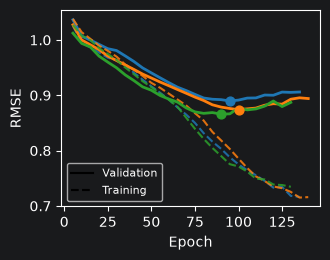

In [15]:
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
rng = np.random.default_rng(SEED)
folds = np.array_split(rng.permutation(len(data.ratings)), N_SPLITS)
cv_histories = []
for k, cand in enumerate(folds):
    mask = np.ones(len(data.ratings), bool); mask[cand] = False
    uc = np.bincount(data.users[mask], minlength=data.n_users)
    ic = np.bincount(data.items[mask], minlength=data.n_items)
    for idx in cand:
        u, i = data.users[idx], data.items[idx]
        if uc[u] == 0 or ic[i] == 0:
            mask[idx] = True; uc[u] += 1; ic[i] += 1
    tr_i, va_i = np.flatnonzero(mask), np.flatnonzero(~mask)
    tr = (data.users[tr_i], data.items[tr_i], data.level_idx[tr_i], data.ratings[tr_i])
    va = (data.users[va_i], data.items[va_i], data.level_idx[va_i], data.ratings[va_i])
    torch.manual_seed(SEED + k); np.random.seed(SEED + k)
    g = RatingGraphs(tr[0], tr[1], tr[2], data.n_users, data.n_items, data.T)
    m = build_model(best_params, build_side(tr, best_params))
    cv_histories.append(make_trainer(m, g, best_params, MAX_EPOCHS).fit(tr, va))
print([round(min(r["val_rmse"] for r in h), 4) for h in cv_histories])

colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
fig, ax = plt.subplots(figsize=(3.4, 2.7))
for k, h in enumerate(cv_histories):
    ep = [r["epoch"] for r in h]; val = [rt["val_rmse"] for r in h]
    ax.plot(ep, [r["train_rmse"] for r in h], "--", color=colors[k], alpha=0.85)
    ax.plot(ep, val, "-", color=colors[k], lw=2)
    j = int(np.argmin(val)); ax.scatter(ep[j], val[j], color=colors[k], s=40, zorder=3)
ax.set(xlabel="Epoch", ylabel="RMSE"); ax.grid(False)
ax.legend(handles=[Line2D([], [], color="k", ls="-", label="Validation"),
                   Line2D([], [], color="k", ls="--", label="Training")], fontsize=8, loc="lower left")
fig.tight_layout(); fig.savefig( ROOT / "results" / "plots" / "fig_cv_curves.pdf")

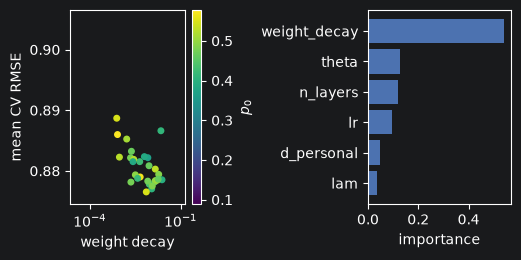

In [16]:
done = [t for t in study.trials if t.value is not None]
wd = np.array([t.params["weight_decay"] for t in done]); val = np.array([t.value for t in done])
p0 = np.array([t.params["p0"] for t in done]); imp = optuna.importance.get_param_importances(study)
fig, ax = plt.subplots(1, 2, figsize=(5.4, 2.7))
sc = ax[0].scatter(wd, val, c=p0, cmap="viridis", s=16); ax[0].set_xscale("log")
ax[0].set_ylim(val.min() - 0.002, val.min() + 0.03)
ax[0].set(xlabel="weight decay", ylabel="mean CV RMSE"); fig.colorbar(sc, ax=ax[0], label="$p_0$")
names = list(imp)[:6][::-1]; ax[1].barh(names, [imp[k] for k in names], color="#4c72b0")
ax[1].set(xlabel="importance"); fig.tight_layout(); fig.savefig( ROOT / "results" / "plots" / "fig_optuna.pdf")

In [17]:
torch.manual_seed(SEED)
np.random.seed(SEED)
full_train = (data.users, data.items, data.level_idx, data.ratings)
full_graphs = RatingGraphs(data.users, data.items, data.level_idx, data.n_users, data.n_items, data.T)
best_model = build_model(best_params, build_side(full_train, best_params))
best_trainer = make_trainer(best_model, full_graphs, best_params, best_epoch, verbose=True)
full_history = best_trainer.fit(full_train)
train_rmse = best_trainer.evaluate(full_train)
print("full-training RMSE:", round(train_rmse, 4))

epoch 5  train_loss 2.2883  train_ce 2.2883  cos_loss -0.0000  cos_mean 0.5665  train_rmse 1.0305  time 0.7379  w_shared 0.1022  w_role 0.1004  w_personal 0.0922  w_genre_year 0.1048  w_dense 0.0731  w_decoder 0.1234  logit_std 2.2491  confidence 0.4031
epoch 10  train_loss 2.1188  train_ce 2.1188  cos_loss -0.0000  cos_mean 0.5945  train_rmse 1.0034  time 1.4556  w_shared 0.0989  w_role 0.0998  w_personal 0.0849  w_genre_year 0.1034  w_dense 0.0720  w_decoder 0.1211  logit_std 2.0027  confidence 0.3135
epoch 15  train_loss 1.9805  train_ce 1.9805  cos_loss -0.0000  cos_mean 0.6242  train_rmse 0.9915  time 2.1781  w_shared 0.0965  w_role 0.0987  w_personal 0.0780  w_genre_year 0.1020  w_dense 0.0710  w_decoder 0.1187  logit_std 1.6691  confidence 0.3367
epoch 20  train_loss 1.9180  train_ce 1.9180  cos_loss -0.0000  cos_mean 0.6547  train_rmse 0.9830  time 2.8995  w_shared 0.0946  w_role 0.0976  w_personal 0.0716  w_genre_year 0.1008  w_dense 0.0701  w_decoder 0.1162  logit_std 1.2544 

In [18]:
levels = torch.as_tensor(data.levels, dtype=torch.float32)
prediction_table = best_model.predict_full(full_graphs, levels).cpu().numpy()      # (n_users, n_items)

R_test = np.load(TEST_DATA_PATH)
assert R_test.shape == data.table.shape, "train and test matrices must have the same shape"
test_mask = np.isfinite(R_test)
test_users, test_items = np.nonzero(test_mask)
test_ratings = R_test[test_mask]
test_predictions = prediction_table[test_users, test_items]
test_rmse = float(np.sqrt(np.mean((test_predictions - test_ratings) ** 2)))
mean_rmse = float(np.sqrt(np.mean((data.global_mean - test_ratings) ** 2)))

print("test ratings:", len(test_ratings), "  overlap with train:", int((test_mask & data.mask).sum()))
print(f"CV RMSE    {study.best_value:.4f}")
print(f"train RMSE {train_rmse:.4f}")
print(f"test RMSE  {test_rmse:.4f}   (predicting the training mean: {mean_rmse:.4f})")

test ratings: 31598   overlap with train: 0
CV RMSE    0.8765
train RMSE 0.8197
test RMSE  0.8775   (predicting the training mean: 1.0369)


In [19]:
rm = lambda p: float(np.sqrt(np.mean((p - test_ratings) ** 2)))
preds, scores = [], []
for seed in range(5):
    torch.manual_seed(seed); np.random.seed(seed)
    m = build_model(best_params, build_side(full_train, best_params))
    make_trainer(m, full_graphs, best_params, best_epoch).fit(full_train)
    p = m.predict_full(full_graphs, levels).cpu().numpy()[test_users, test_items]
    preds.append(p); scores.append(rm(p))
print("per seed:", np.round(scores, 4), "| mean", round(np.mean(scores), 4), "| std", round(np.std(scores), 4))
print("5-seed ensemble test RMSE:", round(rm(np.mean(preds, axis=0)), 4))

per seed: [0.8775 0.8793 0.8734 0.8742 0.8782] | mean 0.8765 | std 0.0023
5-seed ensemble test RMSE: 0.8724


In [20]:
description = best_model.describe()
print("model:", description)

rms = lambda w: w.detach().pow(2).mean().sqrt().item()
emb = best_model.embedding
print("\ntypical size of one number in each group (the starting vectors begin at 0.1):")
print(f"  shared   {rms(emb.shared):.4f}")
print(f"  role     {rms(emb.role.weight):.4f}")
print(f"  personal {rms(emb.personal):.4f}")
for index, name in enumerate(emb.feature_names):
    fixed_input = getattr(emb, f"features_{index}")
    sharing = "shared across rating levels" if emb.share_feature_weights else "one per rating level"
    print(f"  {name:8s} {rms(emb.feat[index]):.4f}   fixed input {tuple(fixed_input.shape)} "
          f"-> learned projection {tuple(emb.feat[index].shape)} ({sharing})")
if best_model.encoder.use_layer_weights:
    for k, w in enumerate(best_model.encoder.layer_w):
        distance = (w.detach().cpu() - torch.eye(w.shape[0])).norm().item()
        print(f"  layer {k} weights: distance from identity {distance:.3f}")
if best_model.side is not None:
    for name, term in zip(("genre",), best_model.side.terms):
        print(f"  {name} profile scale {np.round(term.alpha.detach().cpu().numpy(), 3)}   category bias {rms(term.bias):.4f}")
if best_model.use_bias:
    print(f"  level bias {rms(best_model.level_bias):.4f}   user bias {rms(best_model.user_bias):.4f}   "
          f"item bias {rms(best_model.item_bias):.4f}")

# Ablation: RMSE with one group zeroed. It measures dependence, not the gain of having the group.
test_triples = (test_users, test_items, np.zeros(len(test_users), dtype=int), test_ratings)
train_ablation = best_trainer.ablation(full_train)
test_ablation = best_trainer.ablation(test_triples)
print(f"\n{'':12s} {'train':>8s} {'':>9s} {'test':>8s}")
for name in train_ablation:
    print(f"{name:12s} {train_ablation[name]:8.4f} ({train_ablation[name] - train_ablation['full']:+.4f}) "
          f"{test_ablation[name]:8.4f} ({test_ablation[name] - test_ablation['full']:+.4f})")

model: {'starting_vector': {'shared': 16, 'role': 8, 'genre_year': 4, 'personal': 32}, 'dim': 60, 'features': ['genre_year'], 'share_feature_weights': True, 'n_layers': 3, 'layer_weights': False, 'encoder_dense_bias': True, 'side': False, 'use_bias': False, 'n_parameters': 1833776}

typical size of one number in each group (the starting vectors begin at 0.1):
  shared   0.0964
  role     0.0972
  personal 0.0206
  genre_year 0.0914   fixed input (5590, 20) -> learned projection (20, 4) (shared across rating levels)

                train               test
full           0.8197 (+0.0000)   0.8775 (+0.0000)
no_shared      1.2824 (+0.4628)   1.2983 (+0.4207)
no_role        0.8524 (+0.0327)   0.9096 (+0.0320)
no_personal    0.9862 (+0.1665)   0.9882 (+0.1107)
no_genre_year   0.8511 (+0.0314)   0.9082 (+0.0307)


In [21]:
from datetime import datetime

results_dir = ROOT / "results"
results_dir.mkdir(parents=True, exist_ok=True)
run_id = datetime.now().strftime("%Y%m%d_%H%M%S")
model_path = results_dir / f"imc_gae_{run_id}_{RUN_NAME}.pt"
predictions_path = results_dir / f"imc_gae_predictions_{run_id}_{RUN_NAME}.npy"

checkpoint = {
    "run_name": RUN_NAME,
    "variant": dict(VARIANT),                 # what was switched on, from the configuration cell
    "description": description,               # what the model itself reports
    "feature_names": list(feature_names),
    "title_pca_dim": TITLE_PCA_DIM if "title" in feature_names else None,
    "year_preprocessing": ({
        "encoding": "z-score, median-imputed; appended to row-normalized genres",
        "median": years.median,
        "mean": years.mean,
        "scale": years.scale,
        "n_missing": years.n_missing,
    } if "genre_year" in feature_names else None),
    "best_params": best_params,
    "best_epoch": best_epoch,
    "search": {"n_splits": N_SPLITS, "n_trials": N_TRIALS, "max_epochs": MAX_EPOCHS,
               "eval_every": EVAL_EVERY, "patience": PATIENCE, "seed": SEED},
    # the fixed feature matrices are part of the state dict (features_0, features_1, ...)
    "model_state_dict": {k: v.detach().cpu() for k, v in best_model.state_dict().items()},
    "n_users": data.n_users,
    "n_items": data.n_items,
    "rating_levels": data.levels.tolist(),
    "metrics": {"cv_rmse": float(study.best_value), "train_rmse": float(train_rmse),
                "test_rmse": float(test_rmse)},
    "ablation": {"train": train_ablation, "test": test_ablation},
}
torch.save(checkpoint, model_path)
np.save(predictions_path, prediction_table)
print("saved model:      ", model_path.name)
print("saved predictions:", predictions_path.name)

saved model:       imc_gae_20261021_103734_final2110_without_layer_weights.pt
saved predictions: imc_gae_predictions_20261021_103734_final2110_without_layer_weights.npy


In [22]:
#18/10 18:39

check_params = dict(best_params)                      # Optuna best: lam=0.0, 3 layers, p0=0.55, ...
perm = np.random.default_rng(123).permutation(data.n_items)
ALL_FEATURES["genre_year_shuffled"] = on_film_nodes(genre_year[perm], data.n_users)
check_specs = ["none", "genre_year", "genre_year_shuffled"]
SEEDS = (0, 1, 2)

rows = {}
for spec in check_specs:
    feats = pick_features(spec)
    for seed in SEEDS:
        torch.manual_seed(seed); np.random.seed(seed)
        model = build_model(check_params, build_side(chk_train, check_params), feats=feats)
        trainer = make_trainer(model, chk_graphs, check_params, MAX_EPOCHS)
        history = trainer.fit(chk_train, chk_val)
        best = min(history, key=lambda r: r["val_rmse"])
        rows.setdefault(spec, []).append((best["epoch"], best["val_rmse"], trainer.evaluate(chk_val_few)))
for spec, r in rows.items():
    a = np.array(r)
    print(f"{spec:20s} val {a[:, 1].mean():.4f} ± {a[:, 1].std():.4f} | rare films {a[:, 2].mean():.4f} ± {a[:, 2].std():.4f} | epochs {a[:, 0].astype(int).tolist()}")

none                 val 0.8890 ± 0.0018 | rare films 0.9228 ± 0.0035 | epochs [135, 120, 105]
genre_year           val 0.8826 ± 0.0004 | rare films 0.8985 ± 0.0020 | epochs [120, 115, 95]
genre_year_shuffled  val 0.8894 ± 0.0013 | rare films 0.9175 ± 0.0041 | epochs [120, 120, 110]
